# Portfolio of Evidence: Pipelines and Text Data
**Name:** Sheila Shomang | **Student number:** ST10530465
**Institution:** Rosebank International
**Module:** PDAN 8411w, Programming for Data Analytics 1
**Date:** 2026/11/18

**Client brief:** a medical aid is receiving many negative reviews on Hello Peter. They want (1) the **main areas of concern** and (2) the **general sentiment** of how customers are experiencing the service.

**Approach (two pipelines):**
1. *Areas of concern*: unsupervised topic modelling (TF-IDF + NMF) on the text.
2. *Customer sentiment*: supervised text classification (TF-IDF + chi-square feature selection + Logistic Regression) inside a scikit-learn `Pipeline`.

## 1. Setup

In [1]:
# Standard libraries and scikit-learn tools used throughout
import re, warnings, tempfile, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF, LatentDirichletAllocation
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             normalized_mutual_info_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42                      # fixed seed so every result is reproducible
RESULTS = {}                   # collects the key numbers used in the written report

## 2. Load the data
The file is the *Independent Medical Reviews* dataset (California Department of Managed Health Care). Each row is a dispute between a member and their health plan. The `Findings` column holds the free-text summary and reasoning, which is the text we analyse. `Determination` says whether the health plan's decision was upheld or overturned.

In [2]:
df = pd.read_csv("Independent_Medical_Reviews.csv")
print("Shape (rows, columns):", df.shape)
print()
print(df.dtypes.to_string())
print()
print(df[["Report Year", "Diagnosis Category", "Treatment Category", "Determination", "Type"]].head().to_string())

Shape (rows, columns): (19245, 11)

Reference ID                str
Report Year               int64
Diagnosis Category          str
Diagnosis Sub Category      str
Treatment Category          str
Treatment Sub Category      str
Determination               str
Type                        str
Age Range                   str
Patient Gender              str
Findings                    str

   Report Year      Diagnosis Category                         Treatment Category                       Determination                          Type
0         2016              Infectious                Pharmacy/Prescription Drugs  Overturned Decision of Health Plan             Medical Necessity
1         2016                  Mental                    Mental Health Treatment      Upheld Decision of Health Plan             Medical Necessity
2         2016         Autism Spectrum                   Autism Related Treatment      Upheld Decision of Health Plan             Medical Necessity
3         2016  Pre

## 3. Exploratory Data Analysis (EDA) and cleaning

In [3]:
# 3.1 Data quality: missing values and duplicates
missing = df.isna().sum()
print("Missing values per column:")
print(missing[missing > 0].to_string())
print()
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate Reference IDs:", df["Reference ID"].duplicated().sum())

# Length of each text, in characters (missing text counts as 0)
df["raw_len"] = df["Findings"].fillna("").str.len()
print()
print("Findings length (characters):")
print(df["raw_len"].describe().round(0).to_string())
print("Rows with Findings missing or shorter than 100 characters:", (df["raw_len"] < 100).sum())
RESULTS["n_raw"] = int(len(df))
RESULTS["n_missing_text"] = int(df["Findings"].isna().sum())
RESULTS["n_short_text"] = int((df["raw_len"] < 100).sum())

Missing values per column:
Diagnosis Category          59
Diagnosis Sub Category    1904
Treatment Category         450
Treatment Sub Category    1268
Age Range                 1210
Patient Gender            1210
Findings                    20

Exact duplicate rows: 0
Duplicate Reference IDs: 0

Findings length (characters):
count    19245.0
mean      1216.0
std        794.0
min          0.0
25%        707.0
50%       1039.0
75%       1504.0
max       6962.0
Rows with Findings missing or shorter than 100 characters: 23


Determination
Upheld Decision of Health Plan        10788
Overturned Decision of Health Plan     8457

Share overturned: 0.439

Share overturned by review Type:
                               mean  count
Type                                      
Experimental/Investigational  0.399   5167
Medical Necessity             0.456  13588
Urgent Care                   0.416    490


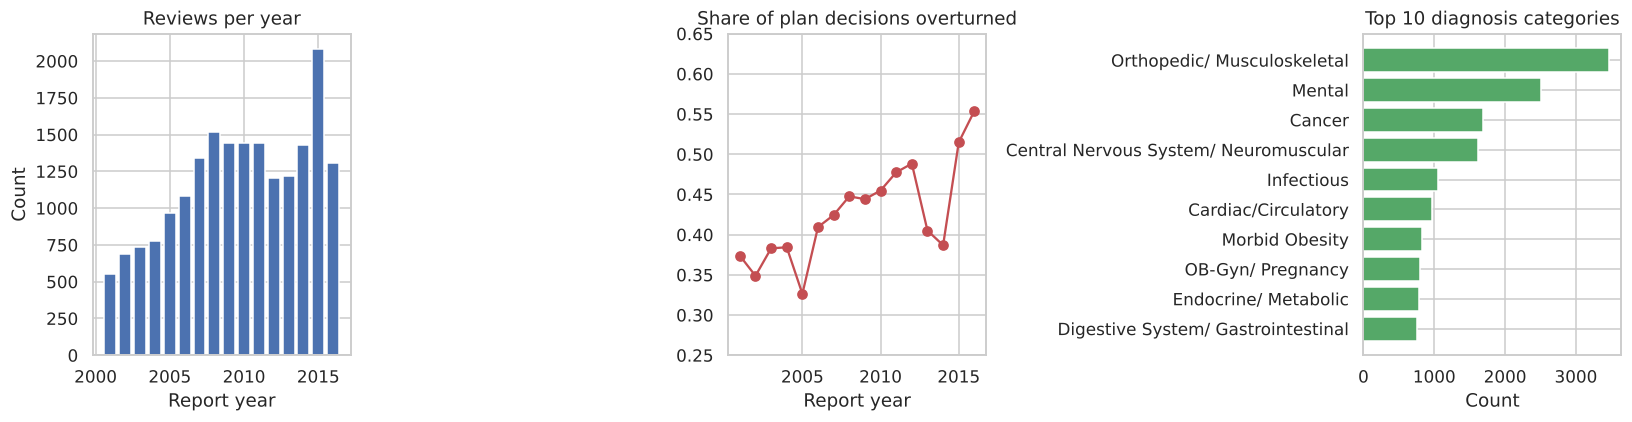

In [4]:
# 3.2 Target and category balance
df["overturned"] = (df["Determination"] == "Overturned Decision of Health Plan").astype(int)
print(df["Determination"].value_counts().to_string())
print("\nShare overturned:", round(df["overturned"].mean(), 3))
print("\nShare overturned by review Type:")
print(df.groupby("Type")["overturned"].agg(["mean", "count"]).round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
yr = df.groupby("Report Year")["overturned"].agg(["count", "mean"])
ax[0].bar(yr.index, yr["count"], color="#4C72B0")
ax[0].set_title("Reviews per year"); ax[0].set_xlabel("Report year"); ax[0].set_ylabel("Count")
ax[1].plot(yr.index, yr["mean"], marker="o", color="#C44E52")
ax[1].set_title("Share of plan decisions overturned"); ax[1].set_xlabel("Report year"); ax[1].set_ylim(0.25, 0.65)
top_dx = df["Diagnosis Category"].value_counts().head(10).sort_values()
ax[2].barh(top_dx.index, top_dx.values, color="#55A868")
ax[2].set_title("Top 10 diagnosis categories"); ax[2].set_xlabel("Count")
plt.tight_layout(); plt.show()

**Cleaning decisions.** (a) Rows with no usable text cannot be analysed, so they are removed. (b) Every text contains boilerplate headings and a *Final Result* sentence that states the outcome (for example "the denial should be overturned"). Keeping that sentence would let the sentiment model simply read the answer (**data leakage**), so any sentence containing the words *overturn* or *uphold* is removed, and the credentials paragraph is cut. (c) Text is lower-cased and reduced to letters only.

In [5]:
# 4. Cleaning function applied to every Findings text
LEAK = re.compile(r"overturn|uphold|upheld", re.I)

def clean_text(txt):
    # Cut the credentials paragraph, which describes the reviewer, not the member's case
    txt = re.split(r"Credentials\s*/?\s*Qualifications", txt, flags=re.I)[0]
    # Remove the standard headings that appear in almost every record
    txt = re.sub(r"Nature of Statutory Criteria\s*/?\s*Case Summary\s*:", " ", txt, flags=re.I)
    txt = re.sub(r"\bFindings\s*:", " ", txt, flags=re.I)
    # Drop any sentence that reveals the outcome (prevents target leakage)
    sentences = re.split(r"(?<=[.!?])\s+", txt)
    sentences = [s for s in sentences if not LEAK.search(s) and not re.match(r"\s*Final result", s, flags=re.I)]
    txt = " ".join(sentences)
    txt = txt.lower()
    txt = re.sub(r"[^a-z\s]", " ", txt)      # keep letters only (removes digits, punctuation)
    return re.sub(r"\s+", " ", txt).strip()

example = df.loc[0, "Findings"]
print("BEFORE:", example[:300], "...")
print()
print("AFTER :", clean_text(example)[:300], "...")

BEFORE: Nature of Statutory Criteria/Case Summary: An enrollee has requested Harvoni for treatment of his hepatitis C virus genotype 1a.  Findings:  The physician reviewer found that according to the most recent joint guidelines issued by the American Association for the Study of Liver Diseases (AASLD) and  ...

AFTER : an enrollee has requested harvoni for treatment of his hepatitis c virus genotype a the physician reviewer found that according to the most recent joint guidelines issued by the american association for the study of liver diseases aasld and the infectious diseases society of america idsa all patient ...


Rows before: 19245 | rows after cleaning: 19203 | removed: 42

Words per cleaned text:
count    19203.0
mean       165.0
std        114.0
min         15.0
25%        100.0
50%        142.0
75%        194.0
max       1059.0


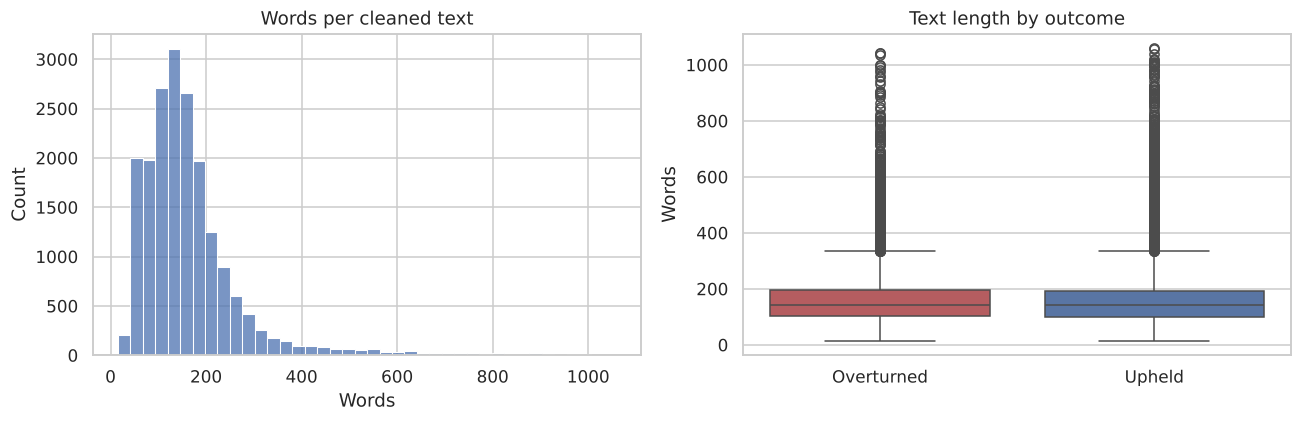

In [6]:
before = len(df)
df = df[df["raw_len"] >= 100].copy()               # remove missing / too-short text
df["text_clean"] = df["Findings"].apply(clean_text)
df["n_words"] = df["text_clean"].str.split().str.len()
df = df[df["n_words"] >= 15].reset_index(drop=True) # remove records that became empty after cleaning
print("Rows before:", before, "| rows after cleaning:", len(df), "| removed:", before - len(df))
print("\nWords per cleaned text:")
print(df["n_words"].describe().round(0).to_string())
RESULTS["n_clean"] = int(len(df))
RESULTS["pct_overturned"] = float(df["overturned"].mean())
RESULTS["words_median"] = float(df["n_words"].median())
RESULTS["n_removed"] = int(before - len(df))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["n_words"], bins=40, ax=ax[0], color="#4C72B0")
ax[0].set_title("Words per cleaned text"); ax[0].set_xlabel("Words")
sns.boxplot(data=df, x="Determination", y="n_words", ax=ax[1], palette=["#C44E52", "#4C72B0"],
            order=["Overturned Decision of Health Plan", "Upheld Decision of Health Plan"])
ax[1].set_xticklabels(["Overturned", "Upheld"]); ax[1].set_xlabel(""); ax[1].set_ylabel("Words")
ax[1].set_title("Text length by outcome")
plt.tight_layout(); plt.show()

Vocabulary size (words appearing in 20+ texts): 4540


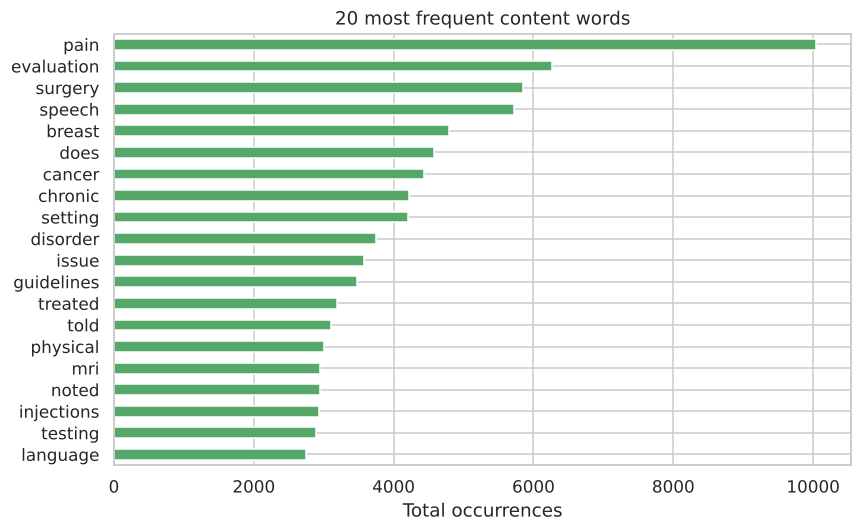

In [7]:
# 5. Most frequent words (after removing common English stop words and generic medical-review words,
# i.e. words that appear in nearly every case and so say nothing about the area of concern)
GENERIC = {"patient","patients","enrollee","enrollees","reviewer","reviewers","physician","found","requested","request","requests",
           "requesting","health","plan","records","review","reviews","reviewed","documentation","documented","document","documents",
           "medical","medically","necessary","necessity","treatment","condition","year","old","male","female","parent","provided",
           "submitted","literature","evidence","clinical","based","support","supported","case","summary","nature","statutory",
           "criteria","findings","result","final","determined","demonstrate","however","therefore","including","may","would",
           "could","given","due","include","use","used","using","per","within","must","requires","need","needs","recommended",
           "recommend","service","services","care","consider","considered","independent","performed","indicating","indicated",
           "indicate","indicates","authorization","coverage","denied","denial","studies","study","efficacy","disease","long",
           "term","standard","available","beneficial","likely","concluded","symptoms","immediate","number","time","times","one",
           "two","also","problem","problems","effective","effectiveness","safety","safe","outcomes","outcome","risk","risks",
           "benefit","benefits","response","history","diagnosis","diagnosed","trial","trials","randomized","controlled",
           "published","peer","experimental","investigational","unproven","proven","therapy","procedure","procedures",
           "medication","medications","drug","drugs","appropriate","specific","current","currently","previous","previously",
           "failed","fail","fails","failure","tried","significant","significantly","sufficient","insufficient","adequate",
           "adequately","help","helps","helpful","improve","improved","improvement","level","levels"}
TOPIC_STOP = list(ENGLISH_STOP_WORDS | GENERIC)

cv = CountVectorizer(stop_words=TOPIC_STOP, token_pattern=r"(?u)\b[a-z]{3,}\b", min_df=20)
counts = cv.fit_transform(df["text_clean"])
freq = pd.Series(np.asarray(counts.sum(axis=0)).ravel(), index=cv.get_feature_names_out()).sort_values(ascending=False)
print("Vocabulary size (words appearing in 20+ texts):", len(freq))
fig, ax = plt.subplots(figsize=(8, 5))
freq.head(20).sort_values().plot.barh(ax=ax, color="#55A868")
ax.set_title("20 most frequent content words"); ax.set_xlabel("Total occurrences")
plt.tight_layout(); plt.show()

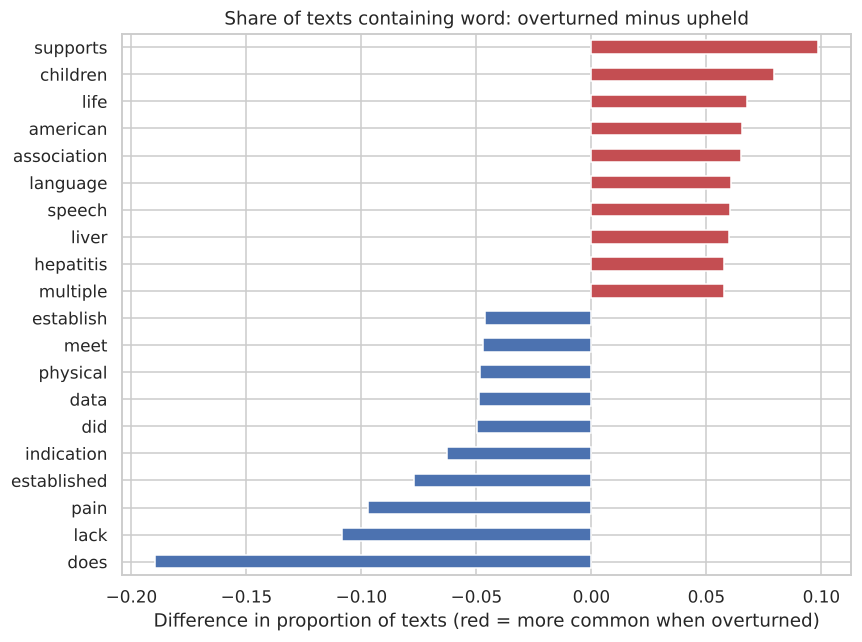

In [8]:
# 6. Words that most separate overturned from upheld cases (a first look at 'sentiment' signal)
cv2 = CountVectorizer(stop_words=TOPIC_STOP, token_pattern=r"(?u)\b[a-z]{3,}\b", min_df=50, binary=True)
B = cv2.fit_transform(df["text_clean"])
words = np.array(cv2.get_feature_names_out())
p_over = np.asarray(B[df["overturned"].values == 1].mean(axis=0)).ravel()
p_up = np.asarray(B[df["overturned"].values == 0].mean(axis=0)).ravel()
diff = pd.Series(p_over - p_up, index=words).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
pd.concat([diff.head(10), diff.tail(10)]).plot.barh(ax=ax, color=["#4C72B0"]*10 + ["#C44E52"]*10)
ax.set_title("Share of texts containing word: overturned minus upheld")
ax.set_xlabel("Difference in proportion of texts (red = more common when overturned)")
plt.tight_layout(); plt.show()

## 7. Pipeline A: Areas of concern (topic modelling)
**Model choice.** Topic modelling is unsupervised, because no one has labelled the concerns in advance. We compare **NMF** (on TF-IDF) with **LDA** (on counts). The number of topics *k* is chosen with a coherence score (do a topic's top words appear together in the same texts?) and by reading the topics. The result is also validated against the dataset's official *Treatment Category* label, which the model never saw.

In [9]:
# TF-IDF for topic modelling: unigrams + bigrams, rare and very common terms removed
tfidf_t = TfidfVectorizer(stop_words=TOPIC_STOP, token_pattern=r"(?u)\b[a-z]{3,}\b",
                          ngram_range=(1, 2), min_df=15, max_df=0.3, sublinear_tf=True)
X_t = tfidf_t.fit_transform(df["text_clean"])
terms = np.array(tfidf_t.get_feature_names_out())
print("Document-term matrix:", X_t.shape)

# Binary version used to compute coherence (does a word pair appear in the same documents?)
Xb = (X_t > 0).astype(np.float32).tocsc()
doc_freq = np.asarray(Xb.sum(axis=0)).ravel()

def umass_coherence(components, top_n=10):
    # Mean UMass coherence across topics: higher (closer to 0) = words in a topic co-occur more
    scores = []
    for comp in components:
        idx = np.argsort(comp)[::-1][:top_n]
        s = 0.0
        for i in range(1, len(idx)):
            for j in range(i):
                co = Xb[:, idx[i]].multiply(Xb[:, idx[j]]).sum()
                s += np.log((co + 1) / doc_freq[idx[j]])
        scores.append(s)
    return float(np.mean(scores))

rows = []
for k in [6, 8, 10, 12, 14]:
    nmf = NMF(n_components=k, init="nndsvd", random_state=SEED, max_iter=300)
    W = nmf.fit_transform(X_t)
    rows.append({"k": k, "coherence": umass_coherence(nmf.components_), "recon_error": nmf.reconstruction_err_})
nmf_grid = pd.DataFrame(rows)
print(nmf_grid.round(3).to_string(index=False))

Document-term matrix: (19203, 11043)
 k  coherence  recon_error
 6    -61.465      134.667
 8    -53.246      133.951
10    -49.887      133.326
12    -50.100      132.842
14    -50.572      132.381


LDA coherence:
 k  coherence
 8   -103.810
10   -114.997
12   -115.901

NMF coherence:
 k  coherence
 6    -61.465
 8    -53.246
10    -49.887
12    -50.100
14    -50.572


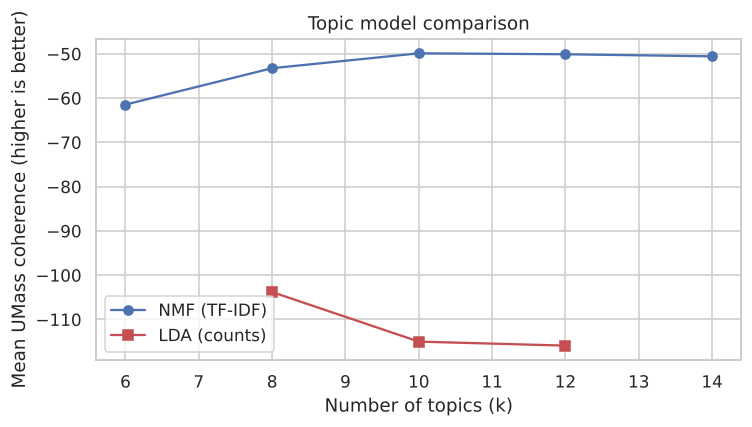

In [10]:
# LDA comparison (needs raw counts, not TF-IDF)
cv_l = CountVectorizer(stop_words=TOPIC_STOP, token_pattern=r"(?u)\b[a-z]{3,}\b",
                       ngram_range=(1, 2), min_df=15, max_df=0.3)
C_l = cv_l.fit_transform(df["text_clean"])
lda_rows = []
for k in [8, 10, 12]:
    lda = LatentDirichletAllocation(n_components=k, learning_method="online", max_iter=8,
                                    random_state=SEED, batch_size=1024)
    lda.fit(C_l)
    # Use the same TF-IDF vocabulary mapping for coherence by re-computing on LDA's own vocabulary
    lda_terms = np.array(cv_l.get_feature_names_out())
    Xb_l = (C_l > 0).astype(np.float32).tocsc()
    df_l = np.asarray(Xb_l.sum(axis=0)).ravel()
    sc = []
    for comp in lda.components_:
        idx = np.argsort(comp)[::-1][:10]; s = 0.0
        for i in range(1, len(idx)):
            for j in range(i):
                s += np.log((Xb_l[:, idx[i]].multiply(Xb_l[:, idx[j]]).sum() + 1) / df_l[idx[j]])
        sc.append(s)
    lda_rows.append({"k": k, "coherence": float(np.mean(sc))})
lda_grid = pd.DataFrame(lda_rows)
print("LDA coherence:"); print(lda_grid.round(3).to_string(index=False))
print("\nNMF coherence:"); print(nmf_grid[["k", "coherence"]].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(nmf_grid["k"], nmf_grid["coherence"], marker="o", label="NMF (TF-IDF)", color="#4C72B0")
ax.plot(lda_grid["k"], lda_grid["coherence"], marker="s", label="LDA (counts)", color="#C44E52")
ax.set_xlabel("Number of topics (k)"); ax.set_ylabel("Mean UMass coherence (higher is better)")
ax.set_title("Topic model comparison"); ax.legend()
plt.tight_layout(); plt.show()
RESULTS["nmf_grid"] = nmf_grid.round(3).to_dict("records")
RESULTS["lda_grid"] = lda_grid.round(3).to_dict("records")

In [11]:
# Fit the chosen NMF model and print each topic's strongest terms for interpretation
K = 10
nmf = NMF(n_components=K, init="nndsvd", random_state=SEED, max_iter=400)
W = nmf.fit_transform(X_t)
H = nmf.components_
for t in range(K):
    top = terms[np.argsort(H[t])[::-1][:10]]
    print(f"Topic {t}: {', '.join(top)}")

Topic 0: pain, disc, physical, knee, surgery, lumbar, chronic, replacement, fusion, mri
Topic 1: hepatitis, harvoni, diseases, liver, genotype, chronic hepatitis, fibrosis, guidelines, weeks, liver diseases
Topic 2: gastric, obesity, bypass, gastric bypass, surgery, morbid, morbid obesity, bypass surgery, surgery morbid, weight
Topic 3: residential, psychiatric, disorder, inpatient, outpatient, program, hospitalization, behavioral, depression, acute
Topic 4: speech, language, children, speech language, autism, delay, skills, expressive, occupational, communication
Topic 5: cancer, pet, scan, evaluation, pet scan, testing, radiation, breast cancer, chemotherapy, breast
Topic 6: emergency, layperson, prudent, prudent layperson, attention, bodily, reasonably, jeopardy, emergent, pain
Topic 7: botox, migraine, botox injections, headaches, injections, migraine headaches, headache, injections migraine, chronic, chronic migraine
Topic 8: growth, growth hormone, hormone, stature, short stature

**Naming the topics.** Names below are written from the top terms above and checked against example texts. They are the analyst's interpretation, not something the algorithm produces.

In [12]:
# Dominant topic per text = the topic with the highest weight in W
df["topic_id"] = W.argmax(axis=1)
for t in range(K):
    print(f"--- Topic {t} example ---")
    ex = df[df["topic_id"] == t].sample(1, random_state=SEED)["text_clean"].iloc[0]
    print(ex[:350], "...\n")

--- Topic 0 example ---
a year old female enrollee has requested for a right total ankle replacement for treatment of her polyarticular arthritis three physician reviewers found that the results of a total ankle arthroplasty as stated in the literature do appear to be similar to those of an ankle fusion one must realize that this individual has had an attempted failed fus ...

--- Topic 1 example ---
an enrollee has requested daklinza with sovaldi for weeks for treatment of her hepatitis c the physician reviewer found that according to joint guidelines issued by the american association for the study of liver diseases and the infectious diseases society of america all patients with chronic hepatitis c should be treated except those with life ex ...

--- Topic 2 example ---
the patient is a year old female with a body mass index bmi of which is diagnostic for super morbid obesity the submitted records indicate the patient has asthma and familial lymphedema it does not appear the patient

                                       reviews  pct_overturned  share_of_all
topic                                                                       
Orthopaedic and chronic pain              5668           0.319         0.295
Cancer scans and treatment                3827           0.387         0.199
Mental health (residential/inpatient)     3160           0.439         0.165
Autism and child speech therapy           1516           0.695         0.079
Obesity (bariatric) surgery               1137           0.503         0.059
Hepatitis C and liver drugs                962           0.726         0.050
Migraine and Botox injections              851           0.457         0.044
Breast cancer screening                    733           0.643         0.038
Growth hormone treatment                   697           0.438         0.036
Emergency care                             652           0.433         0.034


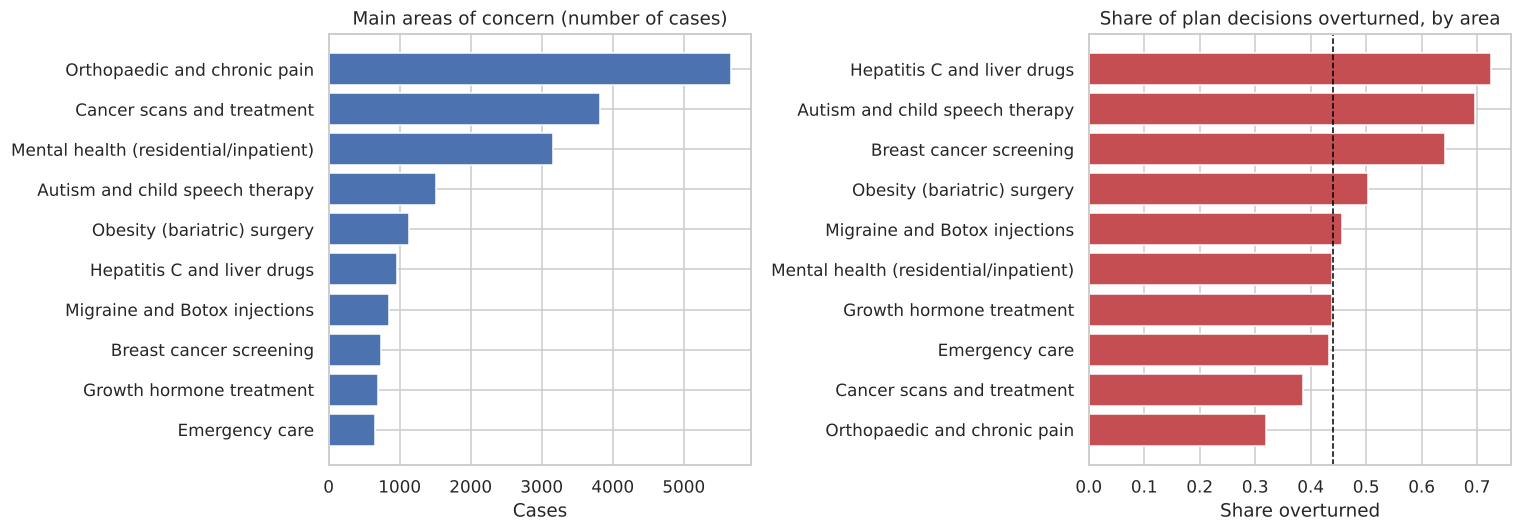

In [13]:
# Topic names (set after reading the term lists and examples above); filled in by TOPIC_NAMES
TOPIC_NAMES = {0: 'Orthopaedic and chronic pain', 1: 'Hepatitis C and liver drugs', 2: 'Obesity (bariatric) surgery', 3: 'Mental health (residential/inpatient)', 4: 'Autism and child speech therapy', 5: 'Cancer scans and treatment', 6: 'Emergency care', 7: 'Migraine and Botox injections', 8: 'Growth hormone treatment', 9: 'Breast cancer screening'}
df["topic"] = df["topic_id"].map(TOPIC_NAMES)
topic_tab = df.groupby("topic").agg(reviews=("overturned", "size"), pct_overturned=("overturned", "mean"))
topic_tab["share_of_all"] = topic_tab["reviews"] / len(df)
topic_tab = topic_tab.sort_values("reviews", ascending=False)
print(topic_tab.round(3).to_string())
RESULTS["topic_tab"] = topic_tab.round(4).reset_index().to_dict("records")
RESULTS["topic_terms"] = {TOPIC_NAMES[t]: list(terms[np.argsort(H[t])[::-1][:8]]) for t in range(K)}

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
tt = topic_tab.sort_values("reviews")
ax[0].barh(tt.index, tt["reviews"], color="#4C72B0"); ax[0].set_title("Main areas of concern (number of cases)")
ax[0].set_xlabel("Cases")
tt2 = topic_tab.sort_values("pct_overturned")
ax[1].barh(tt2.index, tt2["pct_overturned"], color="#C44E52"); ax[1].set_title("Share of plan decisions overturned, by area")
ax[1].axvline(df["overturned"].mean(), color="black", ls="--", lw=1); ax[1].set_xlabel("Share overturned")
plt.tight_layout(); plt.show()

In [14]:
# Validation 1: do the discovered topics agree with the official Treatment Category label?
valid = df.dropna(subset=["Treatment Category"])
nmi = normalized_mutual_info_score(valid["Treatment Category"], valid["topic_id"])
print("Normalised mutual information with official Treatment Category:", round(nmi, 3), "(0 = unrelated, 1 = identical)")

# Validation 2: is the topic related to the outcome? (chi-square test of independence)
ct = pd.crosstab(df["topic"], df["overturned"])
chi, p, dof, _ = chi2_contingency(ct)
print("Chi-square topic vs outcome:", round(chi, 1), "| dof:", dof, "| p-value:", p)
RESULTS["nmi"] = float(nmi); RESULTS["chi2_topic_p"] = float(p)

# Validation 3: stability. Re-fit with different initialisation; how similar are the topic assignments?
nmf_b = NMF(n_components=K, init="random", random_state=7, max_iter=400).fit(X_t)
labels_b = nmf_b.transform(X_t).argmax(axis=1)
stab = normalized_mutual_info_score(df["topic_id"], labels_b)
print("Stability (NMI between two different initialisations):", round(stab, 3))
RESULTS["stability_nmi"] = float(stab)

Normalised mutual information with official Treatment Category: 0.375 (0 = unrelated, 1 = identical)
Chi-square topic vs outcome: 1242.5 | dof: 9 | p-value: 7.986495096854765e-262
Stability (NMI between two different initialisations): 0.725


Change in share (2013-2016 average minus 2001-2008 average), in percentage points:
topic
Obesity (bariatric) surgery              -8.8
Orthopaedic and chronic pain             -5.9
Cancer scans and treatment               -2.8
Migraine and Botox injections            -2.4
Growth hormone treatment                 -1.8
Autism and child speech therapy          -0.2
Emergency care                            1.0
Breast cancer screening                   4.1
Mental health (residential/inpatient)     6.9
Hepatitis C and liver drugs              10.0


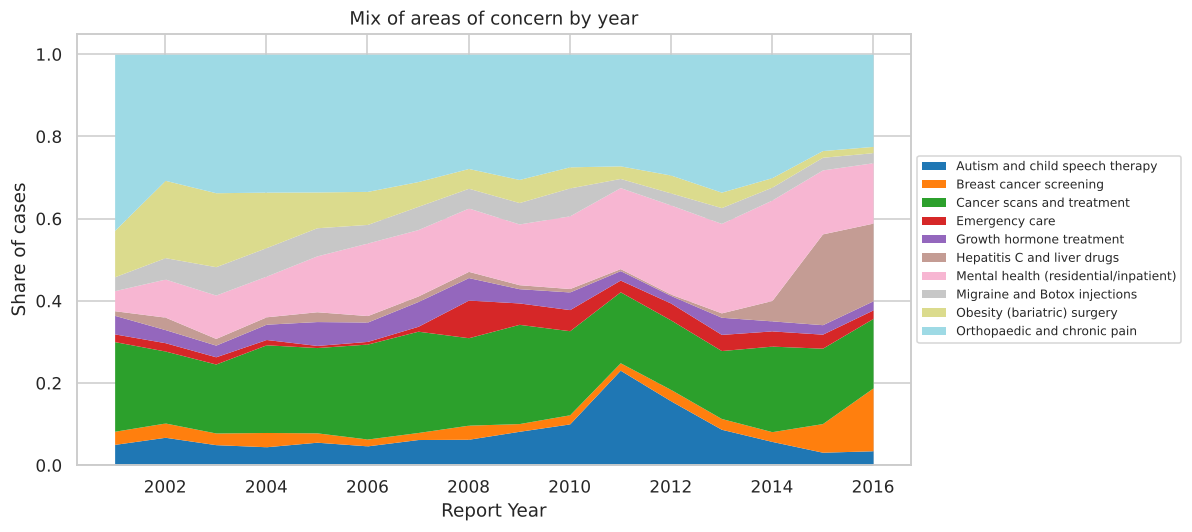

In [15]:
# Trend: how has the mix of concerns changed over time? (share of cases per topic per year)
mix = pd.crosstab(df["Report Year"], df["topic"], normalize="index")
recent = mix.loc[2013:].mean() - mix.loc[2001:2008].mean()
print("Change in share (2013-2016 average minus 2001-2008 average), in percentage points:")
print((recent * 100).sort_values().round(1).to_string())
RESULTS["topic_shift_pp"] = (recent * 100).round(2).to_dict()

fig, ax = plt.subplots(figsize=(11, 5))
mix.plot.area(ax=ax, colormap="tab20", linewidth=0)
ax.set_ylabel("Share of cases"); ax.set_title("Mix of areas of concern by year")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout(); plt.show()

## 8. Pipeline B: Customer sentiment (supervised classification)
**What "sentiment" means here.** The dataset has no star ratings, so sentiment is defined from the independent reviewer's outcome:
- **Negative (1):** the plan's decision was **overturned**, meaning the member's complaint was valid and the plan failed them.
- **Neutral (0):** the plan's decision was **upheld**, meaning the plan acted correctly.

The text model learns the language that goes with each outcome. Negation words (*not*, *no*) are kept, because "not medically necessary" and "medically necessary" mean opposite things.

**Model choice.** Logistic Regression on TF-IDF features: it outputs probabilities, its coefficients show which words drive the result (explainable to a client), and it works well on sparse text. It is compared with Linear SVM and Complement Naive Bayes.

In [16]:
# Stop words for the sentiment model: keep negations because they flip the meaning
NEGATIONS = {"not", "no", "nor", "never", "none", "cannot", "without"}
SENT_STOP = list(ENGLISH_STOP_WORDS - NEGATIONS)

X = df["text_clean"]
y = df["overturned"]
# Stratified 80/20 split: test set is locked away until the final evaluation
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df.index, test_size=0.20, stratify=y, random_state=SEED)
print("Train:", len(X_train), "| Test:", len(X_test))
print("Share negative in train:", round(y_train.mean(), 3), "| in test:", round(y_test.mean(), 3))
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Train: 15362 | Test: 3841
Share negative in train: 0.44 | in test: 0.44


In [17]:
# Helper that scores a fitted pipeline on any data set
def score(model, Xs, ys, name):
    pred = model.predict(Xs)
    if hasattr(model, "predict_proba"):
        s = model.predict_proba(Xs)[:, 1]
    else:
        s = model.decision_function(Xs)
    return {"Model": name, "Accuracy": accuracy_score(ys, pred), "Precision": precision_score(ys, pred),
            "Recall": recall_score(ys, pred), "F1": f1_score(ys, pred), "ROC-AUC": roc_auc_score(ys, s)}

# Model 1: baseline = unigram TF-IDF + Logistic Regression with default settings, no feature selection
model1 = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words=SENT_STOP, token_pattern=r"(?u)\b[a-z]{2,}\b", min_df=5)),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])
model1.fit(X_train, y_train)
n_feat_1 = len(model1.named_steps["tfidf"].get_feature_names_out())
print("Features used by Model 1:", n_feat_1)
cv1 = cross_validate(model1, X_train, y_train, cv=cv5, scoring=["accuracy", "f1", "roc_auc"])
print("Model 1 5-fold CV  accuracy %.4f | F1 %.4f | ROC-AUC %.4f" %
      (cv1["test_accuracy"].mean(), cv1["test_f1"].mean(), cv1["test_roc_auc"].mean()))

Features used by Model 1: 8779
Model 1 5-fold CV  accuracy 0.8691 | F1 0.8473 | ROC-AUC 0.9435


### Feature selection
The vocabulary can run into tens of thousands of terms, most of them noise. A **chi-square test** measures whether each term is statistically related to the outcome and returns a **p-value** per term, which plays the same role as p-values in backward elimination for numeric models. The selector sits *inside* the pipeline so that, during cross-validation, it only ever learns from the training folds.

In [18]:
# Chi-square p-values for each term (training data only)
tf_tmp = TfidfVectorizer(stop_words=SENT_STOP, token_pattern=r"(?u)\b[a-z]{2,}\b", ngram_range=(1, 2), min_df=5)
Xtr_tmp = tf_tmp.fit_transform(X_train)
chi_stat, chi_p = chi2(Xtr_tmp, y_train)
chi_df = pd.DataFrame({"term": tf_tmp.get_feature_names_out(), "chi2": chi_stat, "p_value": chi_p}).sort_values("chi2", ascending=False)
print("Candidate terms (unigrams + bigrams, min_df=5):", len(chi_df))
print("Terms with p < 0.05:", int((chi_df["p_value"] < 0.05).sum()))
print("Terms with p < 0.001:", int((chi_df["p_value"] < 0.001).sum()))
print()
print(chi_df.head(12).to_string(index=False))
RESULTS["n_candidate_terms"] = int(len(chi_df))
RESULTS["n_sig_005"] = int((chi_df["p_value"] < 0.05).sum())
RESULTS["n_sig_001"] = int((chi_df["p_value"] < 0.001).sum())

Candidate terms (unigrams + bigrams, min_df=5): 41040
Terms with p < 0.05: 801
Terms with p < 0.001: 176

           term       chi2      p_value
            not 106.517108 5.680004e-25
         speech  90.649266 1.715356e-21
             no  71.300309 3.067878e-17
       language  70.482855 4.642841e-17
      hepatitis  67.520972 2.084579e-16
       children  59.432562 1.265576e-14
  tomosynthesis  57.803678 2.896277e-14
        harvoni  53.818917 2.198458e-13
     not likely  51.643552 6.654883e-13
speech language  45.846379 1.278993e-11
       does not  45.106052 1.866477e-11
       diseases  41.993073 9.159731e-11


In [19]:
# Model 2: tuned pipeline = TF-IDF -> chi-square selection -> Logistic Regression
# 5-fold CV grid search over n-gram range, number of features kept, regularisation strength C, class weight.
# 'memory' caches the TF-IDF step so identical vectorisers are not refitted for every grid point.
cache_dir = tempfile.mkdtemp()
pipe2 = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words=SENT_STOP, token_pattern=r"(?u)\b[a-z]{2,}\b", min_df=5, sublinear_tf=True)),
    ("select", SelectKBest(chi2)),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
], memory=cache_dir)

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "select__k": [1000, 5000, 20000],
    "clf__C": [0.3, 1, 3, 10],
    "clf__class_weight": [None, "balanced"],
}
grid = GridSearchCV(pipe2, param_grid, cv=cv5, scoring="f1", n_jobs=1, refit=True)
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print("Best cross-validated F1: %.4f" % grid.best_score_)
model2 = grid.best_estimator_
RESULTS["best_params"] = {k: (list(v) if isinstance(v, tuple) else v) for k, v in grid.best_params_.items()}
RESULTS["grid_size"] = int(np.prod([len(v) for v in param_grid.values()]))

res = pd.DataFrame(grid.cv_results_)
top = res.sort_values("rank_test_score").head(5)[["param_tfidf__ngram_range", "param_select__k", "param_clf__C",
                                                   "param_clf__class_weight", "mean_test_score", "std_test_score"]]
print()
print(top.round(4).to_string(index=False))

Best parameters: {'clf__C': 10, 'clf__class_weight': 'balanced', 'select__k': 20000, 'tfidf__ngram_range': (1, 2)}
Best cross-validated F1: 0.8841

param_tfidf__ngram_range  param_select__k  param_clf__C param_clf__class_weight  mean_test_score  std_test_score
                  (1, 2)            20000          10.0                balanced           0.8841          0.0077
                  (1, 2)            20000          10.0                     NaN           0.8825          0.0076
                  (1, 2)             5000          10.0                balanced           0.8819          0.0032
                  (1, 2)            20000           3.0                balanced           0.8814          0.0069
                  (1, 2)             5000          10.0                     NaN           0.8797          0.0049


In [20]:
# Alternative algorithms on the same features (5-fold CV on the training data)
def make(clf):
    return Pipeline([
        ("tfidf", TfidfVectorizer(stop_words=SENT_STOP, token_pattern=r"(?u)\b[a-z]{2,}\b", min_df=5,
                                  ngram_range=grid.best_params_["tfidf__ngram_range"], sublinear_tf=True)),
        ("select", SelectKBest(chi2, k=grid.best_params_["select__k"])),
        ("clf", clf)], memory=cache_dir)

candidates = {
    "Logistic Regression (tuned)": make(LogisticRegression(max_iter=1000, random_state=SEED, C=grid.best_params_["clf__C"],
                                                           class_weight=grid.best_params_["clf__class_weight"])),
    "Linear SVM": make(LinearSVC(C=0.3, random_state=SEED)),
    "Complement Naive Bayes": make(ComplementNB(alpha=0.3)),
}
cmp_rows = []
for name, m in candidates.items():
    r = cross_validate(m, X_train, y_train, cv=cv5, scoring=["accuracy", "f1", "roc_auc"])
    cmp_rows.append({"Model": name, "CV Accuracy": r["test_accuracy"].mean(), "CV F1": r["test_f1"].mean(),
                     "CV ROC-AUC": r["test_roc_auc"].mean()})
cmp_df = pd.DataFrame(cmp_rows)
print(cmp_df.round(4).to_string(index=False))
RESULTS["algo_compare"] = cmp_df.round(4).to_dict("records")
RESULTS["cv_model1"] = {"accuracy": float(cv1["test_accuracy"].mean()), "f1": float(cv1["test_f1"].mean()), "auc": float(cv1["test_roc_auc"].mean())}
RESULTS["cv_model2_f1"] = float(grid.best_score_)

                      Model  CV Accuracy  CV F1  CV ROC-AUC
Logistic Regression (tuned)       0.8976 0.8841      0.9656
                 Linear SVM       0.8974 0.8811      0.9643
     Complement Naive Bayes       0.7986 0.7423      0.8895


## 9. Evaluate on the untouched test set
**Metrics and why.** The positive class is *negative sentiment* (plan overturned), because that is what the client wants to find. **Recall** shows how many truly negative cases we catch, **precision** how many flagged cases really are negative, and **F1** balances both. **ROC-AUC** measures ranking quality across all thresholds. Classes are close to balanced, so accuracy is also meaningful.

                      Model  Accuracy  Precision  Recall     F1  ROC-AUC
          Model 1: baseline    0.8831     0.8837  0.8455 0.8641   0.9488
Model 2: tuned + chi-square    0.9117     0.9004  0.8988 0.8996   0.9702


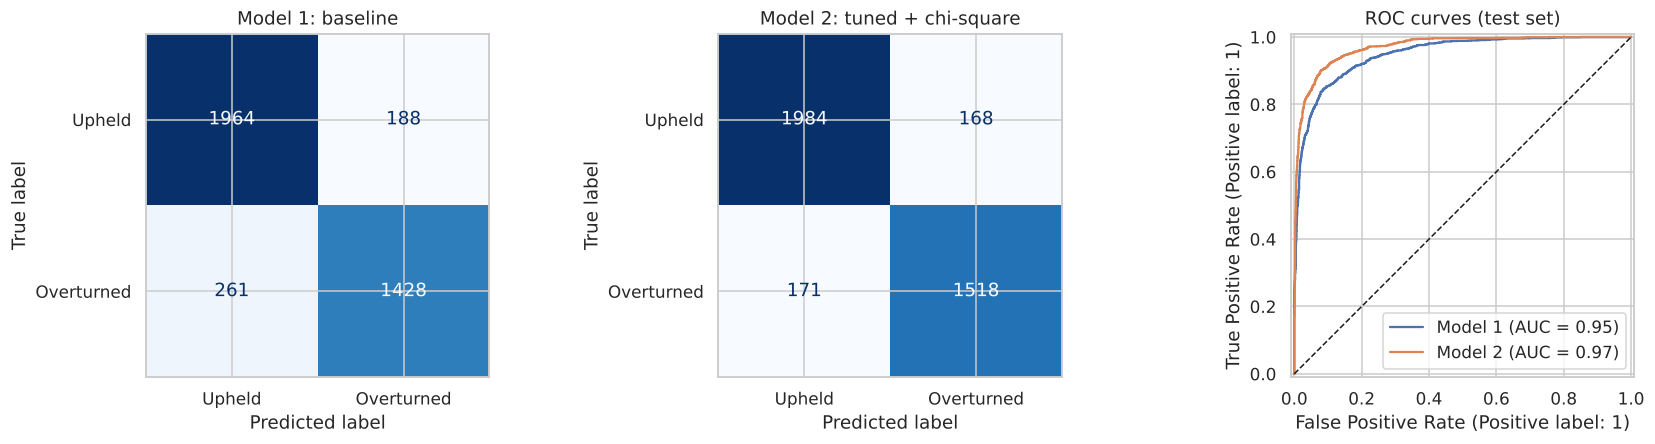

In [21]:
tests = [score(model1, X_test, y_test, "Model 1: baseline"), score(model2, X_test, y_test, "Model 2: tuned + chi-square")]
test_df = pd.DataFrame(tests)
print(test_df.round(4).to_string(index=False))
RESULTS["test_scores"] = test_df.round(4).to_dict("records")

cms = {m["Model"]: confusion_matrix(y_test, mod.predict(X_test)) for m, mod in zip(tests, [model1, model2])}
RESULTS["confusion"] = {k: v.tolist() for k, v in cms.items()}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, (name, mod) in zip(ax[:2], [("Model 1: baseline", model1), ("Model 2: tuned + chi-square", model2)]):
    ConfusionMatrixDisplay(cms[name], display_labels=["Upheld", "Overturned"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(name)
for name, mod in [("Model 1", model1), ("Model 2", model2)]:
    RocCurveDisplay.from_estimator(mod, X_test, y_test, ax=ax[2], name=name)
ax[2].plot([0, 1], [0, 1], "k--", lw=1); ax[2].set_title("ROC curves (test set)")
plt.tight_layout(); plt.show()

In [22]:
# Robustness check 1: a time-based split (train on 2001-2014, test on the most recent years 2015-2016)
# This mimics real use: the model is built on the past and applied to new reviews.
mask_train = (df["Report Year"] <= 2014).values
Xt_tr, Xt_te = df.loc[mask_train, "text_clean"], df.loc[~mask_train, "text_clean"]
yt_tr, yt_te = df.loc[mask_train, "overturned"], df.loc[~mask_train, "overturned"]
from sklearn.base import clone
model2_time = clone(model2).fit(Xt_tr, yt_tr)
time_scores = score(model2_time, Xt_te, yt_te, "Model 2 (time split)")
print("Train rows:", len(Xt_tr), "| Test rows (2015-2016):", len(Xt_te))
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in time_scores.items()})
RESULTS["time_scores"] = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in time_scores.items()}
RESULTS["time_n"] = [int(len(Xt_tr)), int(len(Xt_te))]

Train rows: 15814 | Test rows (2015-2016): 3389
{'Model': 'Model 2 (time split)', 'Accuracy': 0.9587, 'Precision': 0.9554, 'Recall': 0.9671, 'F1': 0.9613, 'ROC-AUC': 0.9911}


In [23]:
# Robustness check 2: is the model just reading the topic? Accuracy by topic on the test set
test_pred = model2.predict(X_test)
by_topic = pd.DataFrame({"topic": df.loc[idx_test, "topic"].values, "ok": (test_pred == y_test.values)})
acc_topic = by_topic.groupby("topic")["ok"].agg(["mean", "count"]).sort_values("mean")
print(acc_topic.round(3).to_string())
RESULTS["acc_by_topic"] = acc_topic.round(3).reset_index().to_dict("records")

                                        mean  count
topic                                              
Obesity (bariatric) surgery            0.836    238
Mental health (residential/inpatient)  0.890    600
Growth hormone treatment               0.890    146
Migraine and Botox injections          0.910    155
Cancer scans and treatment             0.910    780
Breast cancer screening                0.912    160
Autism and child speech therapy        0.921    304
Emergency care                         0.928    125
Orthopaedic and chronic pain           0.932   1140
Hepatitis C and liver drugs            0.953    193


## 10. Interpretation: what language drives negative sentiment?

Terms pushing toward UPHELD (plan was right):
not               -31.37
not medically     -27.70
not likely        -23.15
no                -18.56
not supported     -13.07
not established   -11.78
lack               -9.97
issue not          -9.92
fails              -9.02
records not        -8.26
insufficient       -7.89
services not       -7.41

Terms pushing toward OVERTURNED (member's complaint valid):
therapy likely             6.11
documentation supports     6.36
supports medical           6.38
appropriate indicated      6.53
portion                    8.06
reasonable                 8.30
therapy medically          8.78
medication medically       9.07
supports                   9.30
services medically         9.90
issue medically           10.47
medically                 17.49


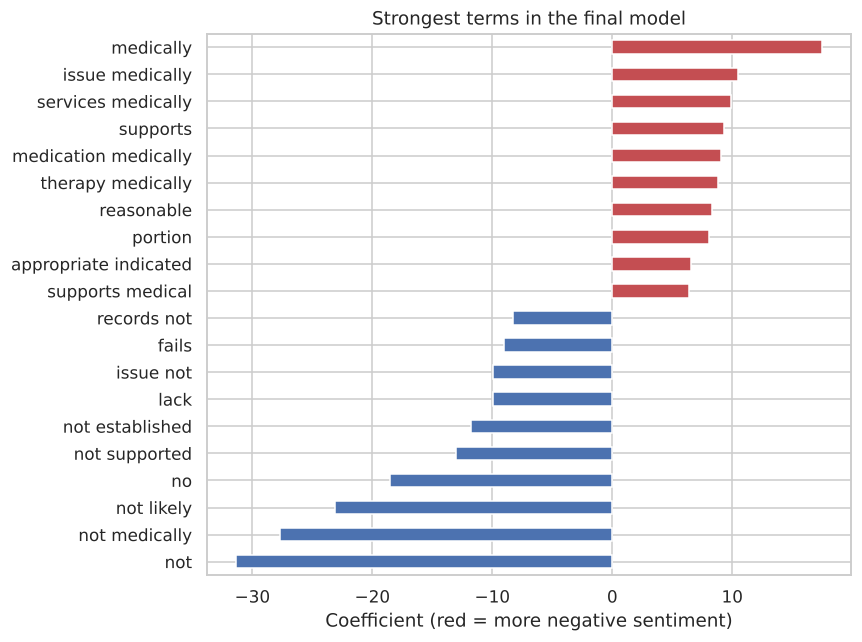

In [24]:
# Map the chosen model's coefficients back to the words they belong to
tfidf_f = model2.named_steps["tfidf"]; sel = model2.named_steps["select"]; clf = model2.named_steps["clf"]
kept = np.array(tfidf_f.get_feature_names_out())[sel.get_support()]
coef = pd.Series(clf.coef_[0], index=kept).sort_values()
print("Terms pushing toward UPHELD (plan was right):"); print(coef.head(12).round(2).to_string())
print("\nTerms pushing toward OVERTURNED (member's complaint valid):"); print(coef.tail(12).round(2).to_string())
RESULTS["coef_up"] = coef.head(10).round(2).to_dict()
RESULTS["coef_over"] = coef.tail(10).round(2).to_dict()

fig, ax = plt.subplots(figsize=(8, 6))
pd.concat([coef.head(10), coef.tail(10)]).plot.barh(ax=ax, color=["#4C72B0"]*10 + ["#C44E52"]*10)
ax.set_title("Strongest terms in the final model"); ax.set_xlabel("Coefficient (red = more negative sentiment)")
plt.tight_layout(); plt.show()

## 11. General customer sentiment: where is it worst?

Overall negative share: 0.440
2001-2008: 0.396 | 2009-2014: 0.443 | 2015-2016: 0.530

Share overturned by area, 2014-2016:
                                        mean  count
topic                                              
Breast cancer screening                0.834    379
Hepatitis C and liver drugs            0.801    778
Autism and child speech therapy        0.574    195
Mental health (residential/inpatient)  0.443    866
Growth hormone treatment               0.438    112
Migraine and Botox injections          0.433    141
Cancer scans and treatment             0.408    901
Obesity (bariatric) surgery            0.379     87
Emergency care                         0.351    151
Orthopaedic and chronic pain           0.290   1211


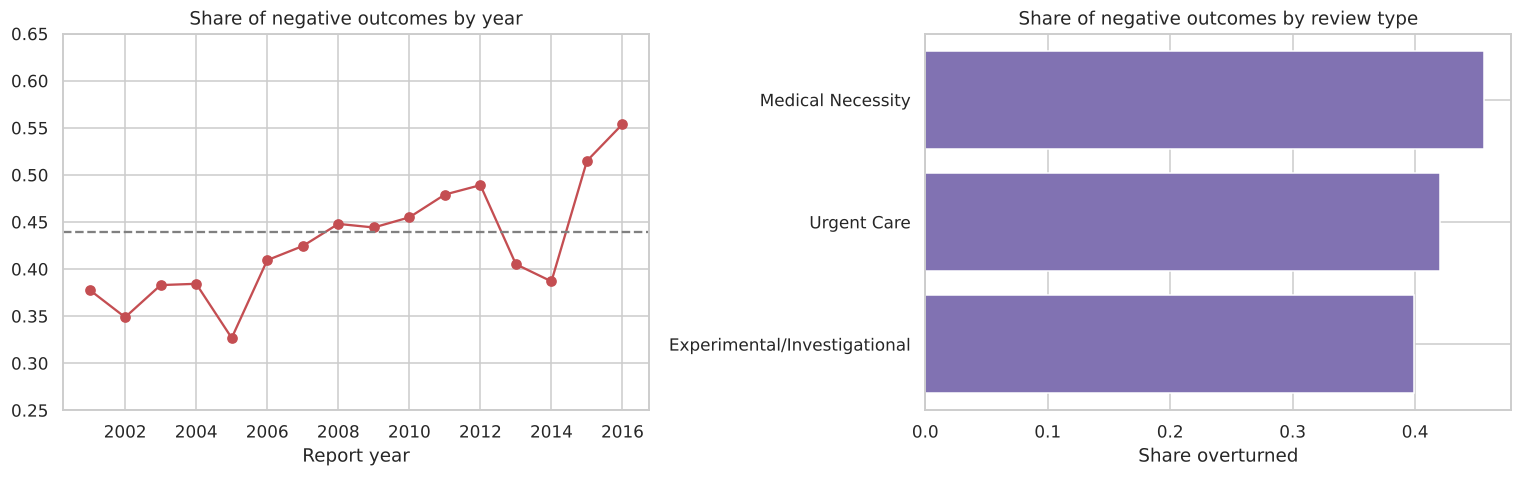

In [25]:
# Overall and over time (observed share of negative outcomes), then by area of concern
yr = df.groupby("Report Year")["overturned"].mean()
print("Overall negative share: %.3f" % df["overturned"].mean())
print("2001-2008: %.3f | 2009-2014: %.3f | 2015-2016: %.3f" % (
    df[df["Report Year"] <= 2008]["overturned"].mean(),
    df[(df["Report Year"] >= 2009) & (df["Report Year"] <= 2014)]["overturned"].mean(),
    df[df["Report Year"] >= 2015]["overturned"].mean()))
RESULTS["yr_rates"] = yr.round(3).to_dict()
RESULTS["period_rates"] = [float(df[df["Report Year"] <= 2008]["overturned"].mean()),
                           float(df[(df["Report Year"] >= 2009) & (df["Report Year"] <= 2014)]["overturned"].mean()),
                           float(df[df["Report Year"] >= 2015]["overturned"].mean())]

# Which areas are worst in the most recent years?
recent_df = df[df["Report Year"] >= 2014]
rec_tab = recent_df.groupby("topic")["overturned"].agg(["mean", "count"]).sort_values("mean", ascending=False)
print("\nShare overturned by area, 2014-2016:")
print(rec_tab.round(3).to_string())
RESULTS["recent_topic_rates"] = rec_tab.round(3).reset_index().to_dict("records")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(yr.index, yr.values, marker="o", color="#C44E52"); ax[0].set_ylim(0.25, 0.65)
ax[0].axhline(df["overturned"].mean(), color="grey", ls="--"); ax[0].set_title("Share of negative outcomes by year")
ax[0].set_xlabel("Report year")
by_type = df.groupby("Type")["overturned"].mean().sort_values()
ax[1].barh(by_type.index, by_type.values, color="#8172B2"); ax[1].set_title("Share of negative outcomes by review type")
ax[1].set_xlabel("Share overturned")
plt.tight_layout(); plt.show()
RESULTS["type_rates"] = by_type.round(3).to_dict()

## 12. Summary of findings
- **Areas of concern:** see the topic table in section 7. The largest areas and the areas with the highest share of overturned decisions are listed there.
- **Sentiment:** the share of negative outcomes is shown overall, over time and by area in section 11.
- **Model:** the tuned Logistic Regression pipeline is compared with the baseline on an untouched test set (section 9) and on a time-based split.

**Limitations.** (1) The data are US (California) cases, not Hello Peter reviews, so results show the method and not South African customers. (2) Sentiment is a proxy, defined from the review outcome. (3) The texts are written by reviewers *after* the decision, so the model reads outcome language and is not a forecast of future complaints. (4) Topic names are the analyst's interpretation.